# Exercise 6: Seismic Noise Attenuation with Convolutional Sparse Coding

- **Course:** PPGEEC2327, Special Topics in Intelligent Information Processing (AI applied to Geophysics), UFRN
- **Reference:** Schuster, G. (2024), *Machine Learning Methods in Geoscience*, SEG, Chapter 15
- **Task:** carry out the lab's Section 6, Exercise: (a) vary the size and the number of filters in the training
  phase, (b) vary the l1 coefficient in the denoising phase, and (c) compare the CSC filters with the filters of
  the first layer of a CNN.
- **Materials:** the lab page was reachable over plain HTTP. The page, its figures, the SEG abstract
  (`CSCdenoising.pdf`), the slides (`csc.pptx`) and the MATLAB code with its data (`csc_code/`) are mirrored at
  `materials/CSC_lab`.

Convolutional sparse coding (CSC) writes an image $\mathbf{x}$ as a sum of $K$ small filters $\mathbf{d}_k$,
each convolved with its own coefficient map $\mathbf{z}_k$, and asks the maps to be sparse:

$$\min_{\mathbf{d},\mathbf{z}}\ \frac{1}{2}\Big\|\mathbf{x}-\sum_{k=1}^{K}\mathbf{d}_k*\mathbf{z}_k\Big\|_2^2
+\beta\sum_{k=1}^{K}\|\mathbf{z}_k\|_1\quad\text{subject to}\quad\|\mathbf{d}_k\|_2^2\le 1. \qquad (1)$$

This is Eq. 1 of the lab and Eq. 15.1 of the book. The lab works in two phases. In the training phase,
`training_phase.m` solves Eq. 1 for both $\mathbf{d}$ and $\mathbf{z}$ on a gather with high signal-to-noise
ratio (SNR). In the denoising phase, `denoise.m` keeps the filters fixed, adds Gaussian noise to a second
gather, and solves Eq. 1 for $\mathbf{z}$ only. The denoised gather is $\sum_k \mathbf{d}_k*\mathbf{z}_k$.
Coherent events are well described by a few shifted filters, while random noise is not, so most of the noise
stays in the misfit.

The notebook ports the MATLAB code to NumPy (Sections 1 and 2), reproduces the lab (Section 3), and then answers
items (a), (b) and (c) in Sections 4, 5 and 6.

## 1. Data and preprocessing

`b.mat` holds five common shot gathers of 181 time samples by 100 traces. As in the MATLAB scripts, the training
image is rows 1 to 100 of gather 1 and the test image is rows 1 to 100 of gather 2. Both go through
`local_contrast_normalization.m` (a 21 x 21 Gaussian window that removes the local mean and divides by the local
standard deviation, floored at its median) and then have their mean removed. The normalization balances the
amplitudes, so that weak late events count as much as strong early ones in the l2 misfit.

b.mat: (181, 100, 5)   training and test images: (100, 100) (100, 100)


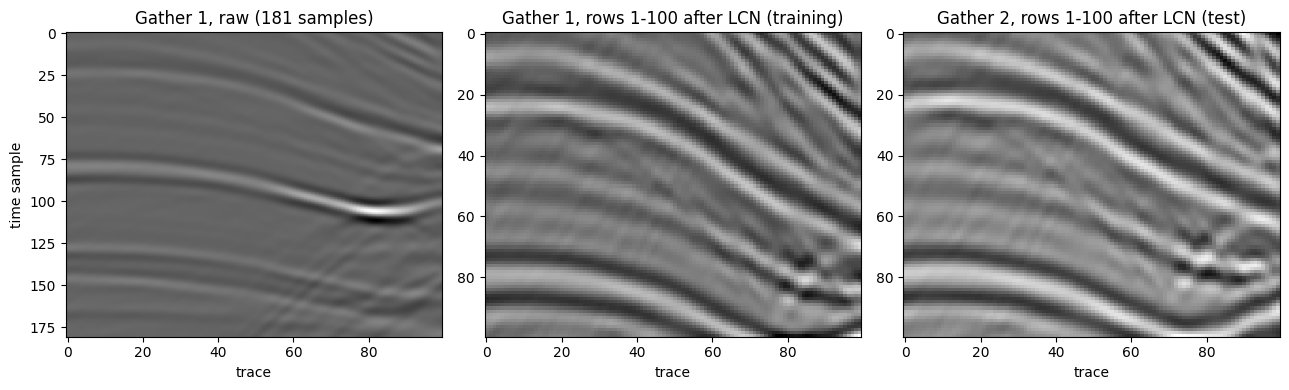

In [1]:
import time

import numpy as np
import scipy.io as sio
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from scipy.signal import convolve2d, correlate2d

LAB = "materials/CSC_lab/csc_code"


def fspecial_gaussian(n, sigma):
    '''MATLAB fspecial('gaussian', [n n], sigma).'''
    s = (n - 1) / 2
    y, x = np.mgrid[-s:s + 1, -s:s + 1]
    h = np.exp(-(x ** 2 + y ** 2) / (2 * sigma ** 2))
    h[h < np.finfo(float).eps * h.max()] = 0
    return h / h.sum()


def rconv2(large, small):
    '''rconv2 from local_contrast_normalization.m: mirror padding without repeating the edge sample.'''
    py, px = (small.shape[0] - 1) // 2, (small.shape[1] - 1) // 2
    return convolve2d(np.pad(large, ((py, py), (px, px)), mode="reflect"), small, mode="valid")


def local_contrast_normalization(img, nk=21):
    '''Port of local_contrast_normalization.m for one 2D image.'''
    k = fspecial_gaussian(nk, 3 * 1.591)
    lmn = rconv2(img, k)
    lstd = np.sqrt(np.maximum(rconv2(img ** 2, k) - lmn ** 2, 0))
    q = np.sort(lstd.ravel())
    th = q[int(np.floor(len(q) / 2 + 0.5)) - 1]  # MATLAB q(round(end/2))
    if th == 0:
        q = q[q != 0]
        th = q[int(np.floor(len(q) / 2 + 0.5)) - 1] if len(q) else 0
    lstd = np.maximum(lstd, th)
    lstd[lstd == 0] = np.finfo(float).eps
    return (img - lmn) / lstd


def snr_db(signal, noise):
    '''snr_test.m: 10 log10(||signal||^2 / ||noise||^2).'''
    return 10 * np.log10(np.sum(signal ** 2) / np.sum(noise ** 2))


b = sio.loadmat(f"{LAB}/b.mat")["b"].astype(float)


def prepare(i):
    '''Rows 1-100 of gather i, local contrast normalization and zero mean, as in training_phase.m and denoise.m.'''
    x = local_contrast_normalization(b[:100, :, i])
    return x - x.mean()


x_train, x_test = prepare(0), prepare(1)
print("b.mat:", b.shape, "  training and test images:", x_train.shape, x_test.shape)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
axes[0].imshow(b[:, :, 0], cmap="gray", aspect="auto")
axes[0].set_title("Gather 1, raw (181 samples)")
axes[1].imshow(x_train, cmap="gray", aspect="auto")
axes[1].set_title("Gather 1, rows 1-100 after LCN (training)")
axes[2].imshow(x_test, cmap="gray", aspect="auto")
axes[2].set_title("Gather 2, rows 1-100 after LCN (test)")
for ax in axes:
    ax.set_xlabel("trace")
axes[0].set_ylabel("time sample")
plt.tight_layout()
plt.show()

## 2. The ADMM solvers

Both MATLAB solvers use the alternating direction method of multipliers (ADMM) in the Fourier domain, following
Heide et al. (2015), which the book cites for Eq. 15.1. The image is padded by the filter radius on each side, a
mask $\mathbf{M}$ (ones inside, zeros on the padding) restricts the misfit to the real samples, and convolutions
become products of spectra. Each ADMM iteration does three things:

1. proximal steps on the two terms that are easy to handle on their own: a weighted average with the data for
   the masked l2 term, and soft thresholding (`soft` below) for the l1 term;
2. a dual update for each splitting;
3. a quadratic step for $\mathbf{z}$ that, at every frequency, inverts a rank-one update of a scaled identity.
   The Sherman-Morrison formula does this in closed form, so the cost is a few FFTs per iteration.

`csc_reconstruct` is the denoising solver (`admm_solve_conv2D_weighted_sparse_reconstruction.m`) with the
all-ones mask of `denoise.m`. The ADMM penalties come from a heuristic of the original code,
$\gamma = 60\beta/\max(\mathbf{x})$, with the data penalty 100 times smaller than the sparsity penalty. With
this choice the soft threshold $\beta/\gamma_2=\max(\mathbf{x})/60$ does not depend on $\beta$: $\beta$ acts
through the weight of the data step. The fixed point of ADMM is still the minimizer of Eq. 1 for that $\beta$,
but after only 80 iterations the run is not fully converged, which Section 5 checks. The returned $\mathbf{z}$
is the variable of the quadratic step, as in the MATLAB code, so it is small but not exactly zero away from the
events.

In [2]:
def fft2(a):
    return np.fft.fft2(a, axes=(0, 1))


def ifft2_real(a):
    return np.real(np.fft.ifft2(a, axes=(0, 1)))


def soft(u, t):
    '''Soft thresholding, the proximal operator of t * ||u||_1 (ProxSparse in the MATLAB code).'''
    return np.sign(u) * np.maximum(np.abs(u) - t, 0)


def crop(a, r):
    return a[r[0]:a.shape[0] - r[0], r[1]:a.shape[1] - r[1]]


def psf2otf(d, size_x):
    '''MATLAB psf2otf for a stack of filters d (h, w, K): zero-pad to size_x, move the center to (0, 0), FFT.'''
    h, w, k = d.shape
    big = np.zeros((size_x[0], size_x[1], k))
    big[:h, :w] = d
    big = np.roll(big, (-(h // 2), -(w // 2)), axis=(0, 1))
    return fft2(big)


def csc_reconstruct(b, d, lambda_residual=1.0, lam=0.5, max_it=80, tol=1e-3, return_info=False):
    '''Port of admm_solve_conv2D_weighted_sparse_reconstruction.m (denoising phase, mask of ones).

    Solves argmin_z lambda_residual/2 ||b - crop(sum_k d_k * z_k)||^2 + lam sum_k ||z_k||_1 with the filters d
    fixed. Returns the coefficients z (padded size) and the reconstruction, which has the size of b.'''
    r = (d.shape[0] // 2, d.shape[1] // 2)
    size_x = (b.shape[0] + 2 * r[0], b.shape[1] + 2 * r[1])
    dhat = psf2otf(d, size_x)
    dhat_sq = np.sum(np.abs(dhat) ** 2, axis=2, keepdims=True)
    M = np.pad(np.ones_like(b), [(r[0], r[0]), (r[1], r[1])])  # M^T M: ones inside, zeros on the padding
    Mtb = np.pad(b, [(r[0], r[0]), (r[1], r[1])])

    gamma_h = 60 * lam / b.max()  # step-size heuristic of the original code
    gamma = (gamma_h / 100, gamma_h)
    rho = gamma[1] / gamma[0]
    theta_data, theta_sparse = lambda_residual / gamma[0], lam / gamma[1]

    K = d.shape[2]
    z = np.zeros(size_x + (K,))
    z_hat = np.zeros(size_x + (K,), dtype=complex)
    dual1, dual2 = np.zeros(size_x), np.zeros(size_x + (K,))
    it = 0
    for it in range(1, max_it + 1):
        v1 = ifft2_real(np.sum(dhat * z_hat, axis=2))
        v2 = z
        u1 = (Mtb + (v1 - dual1) / theta_data) / (M + 1 / theta_data)  # prox of the masked data term
        u2 = soft(v2 - dual2, theta_sparse)  # prox of the l1 term
        dual1 = dual1 - (v1 - u1)
        dual2 = dual2 - (v2 - u2)
        xi1_hat, xi2_hat = fft2(u1 + dual1), fft2(u2 + dual2)
        # z = (D^H D + rho I)^-1 (D^H xi1 + rho xi2), one Sherman-Morrison inverse per frequency
        rhs = np.conj(dhat) * xi1_hat[..., None] + rho * xi2_hat
        z_hat = rhs / rho - np.conj(dhat) * np.sum(dhat * rhs, axis=2, keepdims=True) / (rho + dhat_sq) / rho
        z_old, z = z, ifft2_real(z_hat)
        if np.linalg.norm(z - z_old) / np.linalg.norm(z) < tol:
            break
    rec = crop(ifft2_real(np.sum(dhat * z_hat, axis=2)), r)
    if return_info:
        return z, rec, it
    return z, rec


def csc_objective(z, d_hat, b, lambda_residual, lam, r):
    '''objectiveFunction of the MATLAB learning code: data misfit on the unpadded area plus lam ||z||_1.'''
    Dz = ifft2_real(np.sum(d_hat[..., None] * fft2(z), axis=2))
    return lambda_residual / 2 * np.sum((crop(Dz, r) - b) ** 2) + lam * np.sum(np.abs(z))

def csc_learn(b, kernel_size, lambda_residual=1.0, lam=1.0, max_it=80, tol=1e-3, rng=None, keep_real=True,
trace=None): '''Port of admm_learn_conv2D_weighted_test.m (training phase).

b is (m, n) or (m, n, N); kernel_size is (h, w, K). Each outer iteration runs 10 ADMM iterations on the filters
and then 10 on the coefficients. keep_real=True re-projects d_hat and z_hat onto real signals after each solve
(see Section 3.2); keep_real=False is the MATLAB code as distributed. If trace is a list, it receives the
relative size of the non-real part of z_hat after each outer iteration. Returns the filters (h, w, K), the
coefficients and the objective after each outer iteration.''' rng = np.random.default_rng() if rng is None else
rng if b.ndim == 2: b = b[..., None] h, w, K = kernel_size n = b.shape[2] r = (h // 2, w // 2) size_x =
(b.shape[0] + 2 * r[0], b.shape[1] + 2 * r[1]) sk = (2 * r[0] + 1, 2 * r[1] + 1)

M = np.pad(np.ones_like(b), [(r[0], r[0]), (r[1], r[1]), (0, 0)]) Mtb = np.pad(b, [(r[0], r[0]), (r[1], r[1]),
(0, 0)])

def prox_data(u, theta): return (Mtb + u / theta) / (M + 1 / theta)

def prox_kernel(u): '''Projection onto C = {d : support of size sk, ||d_k||_2 <= 1} (KernelConstraintProj).''' p
= np.roll(u, r, axis=(0, 1))[:sk[0], :sk[1]] nrm = np.sum(p ** 2, axis=(0, 1)) p = np.where(nrm >= 1, p /
np.sqrt(np.maximum(nrm, 1)), p) out = np.zeros_like(u) out[:sk[0], :sk[1]] = p return np.roll(out, (-r[0],
-r[1]), axis=(0, 1))

gamma_h = 60 * lam / b.max() gammas_D = (gamma_h / 5000, gamma_h) gammas_Z = (gamma_h / 500, gamma_h) rho_D =
gammas_D[1] / gammas_D[0] rho_Z = gammas_Z[1] / gammas_Z[0]

d = np.zeros(size_x + (K,)) d[:h, :w] = rng.standard_normal((h, w, K)) d = np.roll(d, (-r[0], -r[1]), axis=(0,
1)) d_hat = fft2(d) z = rng.standard_normal(size_x + (K, n)) z_hat = fft2(z)

obj_val = csc_objective(z, d_hat, b, lambda_residual, lam, r) history = [obj_val] obj_filter = obj_z = obj_val
dualD = [np.zeros(size_x + (n,)), np.zeros(size_x + (K,))] dualZ = [np.zeros(size_x + (n,)), np.zeros(size_x +
(K, n))]

for _ in range(max_it): # filter update: at each frequency, A (n x K) holds the coefficient spectra of the N
images A = np.transpose(z_hat, (0, 1, 3, 2)) Ah = np.conj(np.swapaxes(A, -1, -2)) AAh = A @ Ah + rho_D *
np.eye(n) obj_min = min(obj_filter, obj_z) d_old, d_hat_old = d, d_hat for _ in range(10): v1 =
ifft2_real(np.sum(d_hat[..., None] * z_hat, axis=2)) v2 = d u1 = prox_data(v1 - dualD[0], lambda_residual /
gammas_D[0]) u2 = prox_kernel(v2 - dualD[1]) dualD[0] = dualD[0] - (v1 - u1) dualD[1] = dualD[1] - (v2 - u2)
xi1_hat, xi2_hat = fft2(u1 + dualD[0]), fft2(u2 + dualD[1]) # Woodbury: (A^H A + rho I)^-1 = (I - A^H (rho I + A
A^H)^-1 A) / rho rhs = (Ah @ xi1_hat[..., None])[..., 0] + rho_D * xi2_hat d_hat = (rhs - (Ah @
np.linalg.solve(AAh, A @ rhs[..., None]))[..., 0]) / rho_D d = ifft2_real(d_hat) if keep_real: d_hat = fft2(d)
obj_filter = csc_objective(z, d_hat, b, lambda_residual, lam, r) d_diff = np.linalg.norm(d - d_old) /
np.linalg.norm(d)

# coefficient update: Sherman-Morrison per image and frequency, as in the denoising solver dh = d_hat[..., None]
dhat_sq = np.sum(np.abs(dh) ** 2, axis=2, keepdims=True) z_old, z_hat_old = z, z_hat for _ in range(10): v1 =
ifft2_real(np.sum(dh * z_hat, axis=2)) v2 = z u1 = prox_data(v1 - dualZ[0], lambda_residual / gammas_Z[0]) u2 =
soft(v2 - dualZ[1], lam / gammas_Z[1]) dualZ[0] = dualZ[0] - (v1 - u1) dualZ[1] = dualZ[1] - (v2 - u2) xi1_hat,
xi2_hat = fft2(u1 + dualZ[0]), fft2(u2 + dualZ[1]) rhs = np.conj(dh) * xi1_hat[:, :, None, :] + rho_Z * xi2_hat
z_hat = rhs / rho_Z - np.conj(dh) * np.sum(dh * rhs, axis=2, keepdims=True) / (rho_Z + dhat_sq) / rho_Z z =
ifft2_real(z_hat) if keep_real: z_hat = fft2(z) obj_z = csc_objective(z, d_hat, b, lambda_residual, lam, r) if
trace is not None: trace.append(np.linalg.norm(fft2(z) - z_hat) / np.linalg.norm(z_hat))

if obj_min <= obj_filter and obj_min <= obj_z: # neither block improved on the previous iterate: restore it and
stop, as the MATLAB code does z, z_hat, d, d_hat = z_old, z_hat_old, d_old, d_hat_old break
history.append(obj_z) z_diff = np.linalg.norm(z - z_old) / np.linalg.norm(z) if z_diff < tol and d_diff < tol:
break d_out = np.roll(d, r, axis=(0, 1))[:sk[0], :sk[1]] return d_out, z, np.array(history)

In [3]:
def csc_learn(b, kernel_size, lambda_residual=1.0, lam=1.0, max_it=80, tol=1e-3, rng=None, keep_real=True,
              trace=None):
    '''Port of admm_learn_conv2D_weighted_test.m (training phase).

    b is (m, n) or (m, n, N); kernel_size is (h, w, K). Each outer iteration runs 10 ADMM iterations on the
    filters and then 10 on the coefficients. keep_real=True re-projects d_hat and z_hat onto real signals after
    each solve (see Section 3.2); keep_real=False is the MATLAB code as distributed. If trace is a list, it
    receives the relative size of the non-real part of z_hat after each outer iteration. Returns the filters
    (h, w, K), the coefficients and the objective after each outer iteration.'''
    rng = np.random.default_rng() if rng is None else rng
    if b.ndim == 2:
        b = b[..., None]
    h, w, K = kernel_size
    n = b.shape[2]
    r = (h // 2, w // 2)
    size_x = (b.shape[0] + 2 * r[0], b.shape[1] + 2 * r[1])
    sk = (2 * r[0] + 1, 2 * r[1] + 1)

    M = np.pad(np.ones_like(b), [(r[0], r[0]), (r[1], r[1]), (0, 0)])
    Mtb = np.pad(b, [(r[0], r[0]), (r[1], r[1]), (0, 0)])

    def prox_data(u, theta):
        return (Mtb + u / theta) / (M + 1 / theta)

    def prox_kernel(u):
        '''Projection onto C = {d : support of size sk, ||d_k||_2 <= 1} (KernelConstraintProj).'''
        p = np.roll(u, r, axis=(0, 1))[:sk[0], :sk[1]]
        nrm = np.sum(p ** 2, axis=(0, 1))
        p = np.where(nrm >= 1, p / np.sqrt(np.maximum(nrm, 1)), p)
        out = np.zeros_like(u)
        out[:sk[0], :sk[1]] = p
        return np.roll(out, (-r[0], -r[1]), axis=(0, 1))

    gamma_h = 60 * lam / b.max()
    gammas_D = (gamma_h / 5000, gamma_h)
    gammas_Z = (gamma_h / 500, gamma_h)
    rho_D = gammas_D[1] / gammas_D[0]
    rho_Z = gammas_Z[1] / gammas_Z[0]

    d = np.zeros(size_x + (K,))
    d[:h, :w] = rng.standard_normal((h, w, K))
    d = np.roll(d, (-r[0], -r[1]), axis=(0, 1))
    d_hat = fft2(d)
    z = rng.standard_normal(size_x + (K, n))
    z_hat = fft2(z)

    obj_val = csc_objective(z, d_hat, b, lambda_residual, lam, r)
    history = [obj_val]
    obj_filter = obj_z = obj_val
    dualD = [np.zeros(size_x + (n,)), np.zeros(size_x + (K,))]
    dualZ = [np.zeros(size_x + (n,)), np.zeros(size_x + (K, n))]

    for _ in range(max_it):
        # filter update: at each frequency, A (n x K) holds the coefficient spectra of the N images
        A = np.transpose(z_hat, (0, 1, 3, 2))
        Ah = np.conj(np.swapaxes(A, -1, -2))
        AAh = A @ Ah + rho_D * np.eye(n)
        obj_min = min(obj_filter, obj_z)
        d_old, d_hat_old = d, d_hat
        for _ in range(10):
            v1 = ifft2_real(np.sum(d_hat[..., None] * z_hat, axis=2))
            v2 = d
            u1 = prox_data(v1 - dualD[0], lambda_residual / gammas_D[0])
            u2 = prox_kernel(v2 - dualD[1])
            dualD[0] = dualD[0] - (v1 - u1)
            dualD[1] = dualD[1] - (v2 - u2)
            xi1_hat, xi2_hat = fft2(u1 + dualD[0]), fft2(u2 + dualD[1])
            # Woodbury: (A^H A + rho I)^-1 = (I - A^H (rho I + A A^H)^-1 A) / rho
            rhs = (Ah @ xi1_hat[..., None])[..., 0] + rho_D * xi2_hat
            d_hat = (rhs - (Ah @ np.linalg.solve(AAh, A @ rhs[..., None]))[..., 0]) / rho_D
            d = ifft2_real(d_hat)
            if keep_real:
                d_hat = fft2(d)
        obj_filter = csc_objective(z, d_hat, b, lambda_residual, lam, r)
        d_diff = np.linalg.norm(d - d_old) / np.linalg.norm(d)

        # coefficient update: Sherman-Morrison per image and frequency, as in the denoising solver
        dh = d_hat[..., None]
        dhat_sq = np.sum(np.abs(dh) ** 2, axis=2, keepdims=True)
        z_old, z_hat_old = z, z_hat
        for _ in range(10):
            v1 = ifft2_real(np.sum(dh * z_hat, axis=2))
            v2 = z
            u1 = prox_data(v1 - dualZ[0], lambda_residual / gammas_Z[0])
            u2 = soft(v2 - dualZ[1], lam / gammas_Z[1])
            dualZ[0] = dualZ[0] - (v1 - u1)
            dualZ[1] = dualZ[1] - (v2 - u2)
            xi1_hat, xi2_hat = fft2(u1 + dualZ[0]), fft2(u2 + dualZ[1])
            rhs = np.conj(dh) * xi1_hat[:, :, None, :] + rho_Z * xi2_hat
            z_hat = rhs / rho_Z - np.conj(dh) * np.sum(dh * rhs, axis=2, keepdims=True) / (rho_Z + dhat_sq) / rho_Z
            z = ifft2_real(z_hat)
            if keep_real:
                z_hat = fft2(z)
        obj_z = csc_objective(z, d_hat, b, lambda_residual, lam, r)
        if trace is not None:
            trace.append(np.linalg.norm(fft2(z) - z_hat) / np.linalg.norm(z_hat))

        if obj_min <= obj_filter and obj_min <= obj_z:
            # neither block improved on the previous iterate: restore it and stop, as the MATLAB code does
            z, z_hat, d, d_hat = z_old, z_hat_old, d_old, d_hat_old
            break
        history.append(obj_z)
        z_diff = np.linalg.norm(z - z_old) / np.linalg.norm(z)
        if z_diff < tol and d_diff < tol:
            break
    d_out = np.roll(d, r, axis=(0, 1))[:sk[0], :sk[1]]
    return d_out, z, np.array(history)

## 3. Reproducing the lab

### 3.1 Training and denoising with the lab's settings

`training_phase.m` learns $K=3$ filters of 21 x 11 samples with $\beta=1$, `max_it = 80` and `tol = 1e-3`. The
`filters.mat` shipped with the lab holds the filters the author obtained with these settings, so they serve as a
reference for the port.

training (21 x 11 x 3): 26 outer iterations, 1.0 s, final objective 569.3
objective stored in the lab's filters.mat: 576.2


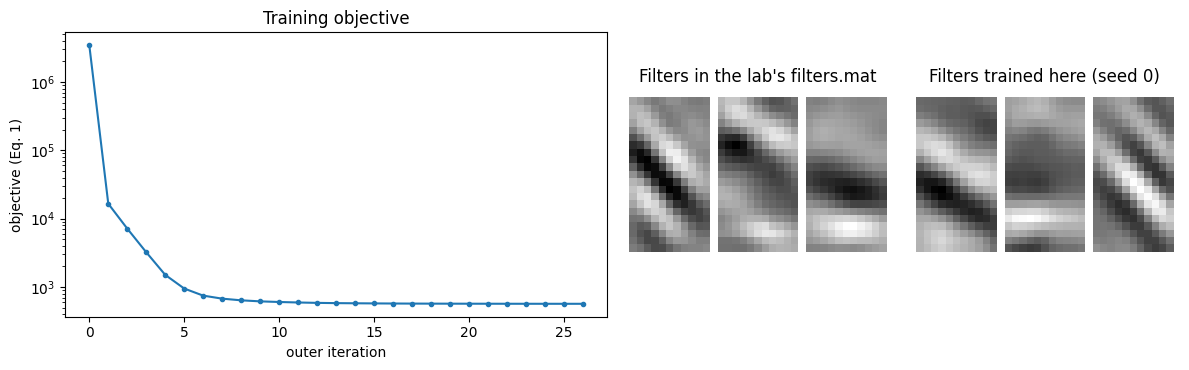

In [4]:
def mosaic(d, ncols=None, pad=1):
    '''Tile filters (h, w, K) into one image, each scaled to [-1, 1], like the display code of training_phase.m.'''
    h, w, K = d.shape
    ncols = ncols or int(np.ceil(np.sqrt(K)))
    nrows = int(np.ceil(K / ncols))
    out = np.full((nrows * (h + pad) + pad, ncols * (w + pad) + pad), np.nan)
    for k in range(K):
        i, j = divmod(k, ncols)
        out[pad + i * (h + pad):pad + i * (h + pad) + h, pad + j * (w + pad):pad + j * (w + pad) + w] = \
            d[:, :, k] / np.abs(d[:, :, k]).max()
    return out


def show_mosaic(ax, d, title, ncols=None):
    cmap = plt.get_cmap("gray").copy()
    cmap.set_bad("white")
    ax.imshow(mosaic(d, ncols), cmap=cmap, vmin=-1, vmax=1)
    ax.set_title(title)
    ax.axis("off")


lab = sio.loadmat(f"{LAB}/filters.mat")
d_lab = lab["d"]

t0 = time.time()
d_own, z_own, hist_own = csc_learn(x_train, (21, 11, 3), rng=np.random.default_rng(0))
print(f"training (21 x 11 x 3): {len(hist_own) - 1} outer iterations, {time.time() - t0:.1f} s, "
      f"final objective {hist_own[-1]:.1f}")
print(f"objective stored in the lab's filters.mat: {lab['obj'].item():.1f}")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), gridspec_kw={"width_ratios": [2, 1, 1]})
axes[0].semilogy(hist_own, "o-", ms=3)
axes[0].set_xlabel("outer iteration")
axes[0].set_ylabel("objective (Eq. 1)")
axes[0].set_title("Training objective")
show_mosaic(axes[1], d_lab, "Filters in the lab's filters.mat", ncols=3)
show_mosaic(axes[2], d_own, "Filters trained here (seed 0)", ncols=3)
plt.tight_layout()
plt.show()

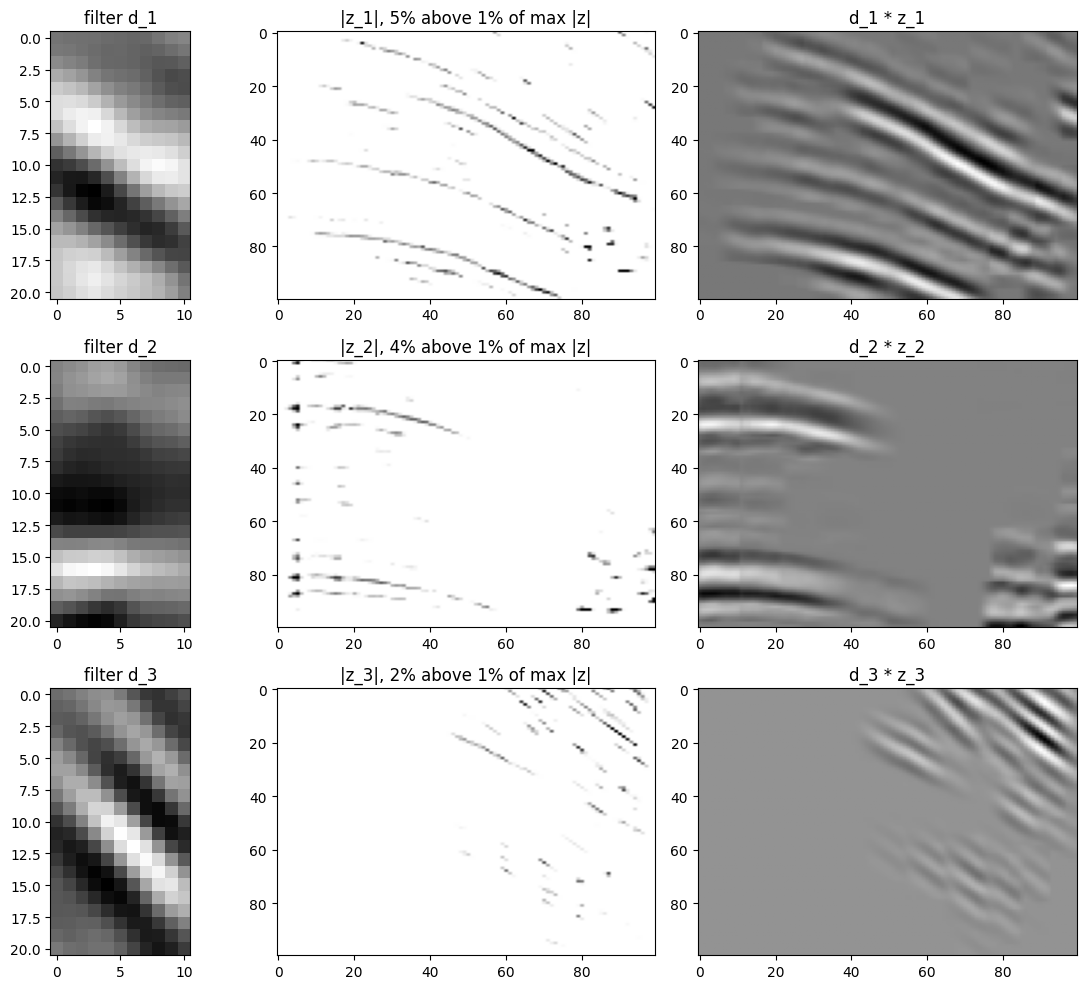

training image fit: SNR of sum_k d_k * z_k against x_train = 12.69 dB


In [5]:
r = (10, 5)
size_x = (x_train.shape[0] + 2 * r[0], x_train.shape[1] + 2 * r[1])
dz = ifft2_real(psf2otf(d_own, size_x) * fft2(z_own[:, :, :, 0]))  # d_k * z_k for each k
zmax = np.abs(z_own).max()

fig, axes = plt.subplots(3, 3, figsize=(11, 10), gridspec_kw={"width_ratios": [0.6, 1, 1]})
for k in range(3):
    axes[k, 0].imshow(d_own[:, :, k], cmap="gray")
    axes[k, 0].set_title(f"filter d_{k + 1}")
    zk = np.abs(crop(z_own[:, :, k, 0], r))
    axes[k, 1].imshow(zk, cmap="gray_r", vmax=0.5 * zmax, aspect="auto")
    axes[k, 1].set_title(f"|z_{k + 1}|, {np.mean(zk > 0.01 * zmax):.0%} above 1% of max |z|")
    axes[k, 2].imshow(crop(dz[:, :, k], r), cmap="gray", aspect="auto")
    axes[k, 2].set_title(f"d_{k + 1} * z_{k + 1}")
plt.tight_layout()
plt.show()

rec_train = crop(dz.sum(axis=2), r)
print(f"training image fit: SNR of sum_k d_k * z_k against x_train = {snr_db(x_train, rec_train - x_train):.2f} dB")

Training stops after 26 outer iterations with an objective of 569.3, close to the 576.2 stored in the lab's
`filters.mat`. The two filter sets are not identical (the start is random, and filters are only defined up to
order and sign), but they are the same kind of object: each filter is a short piece of a seismic event, a
wavelet of two or three lobes stretched along one dip. Ours split the gather into a moderate dip
($\mathbf{d}_1$), a nearly flat dip ($\mathbf{d}_2$) and a steep dip ($\mathbf{d}_3$).

The coefficient maps show how the gather is divided among the filters. Each map is large only along the events
whose dip matches its filter: $\mathbf{z}_1$ follows the main dipping events, $\mathbf{z}_2$ the flat events on
the left and at the right edge, and $\mathbf{z}_3$ the steep events at the upper right. Only 2% to 5% of each
map is above 1% of the largest coefficient, so the representation is sparse even though the returned
$\mathbf{z}$ is not exactly zero elsewhere (Section 2). The sum of the three partial images fits the training
gather with an SNR of 12.69 dB; the misfit is what the l1 term with $\beta=1$ trades for sparsity.

noise seed 100: SNR noisy 7.10 dB, denoised with the lab filters 15.27 dB, with our filters 15.19 dB


noise seeds 100-104: noisy 7.12, lab filters 15.33 +- 0.12, our filters 15.29 +- 0.08 dB


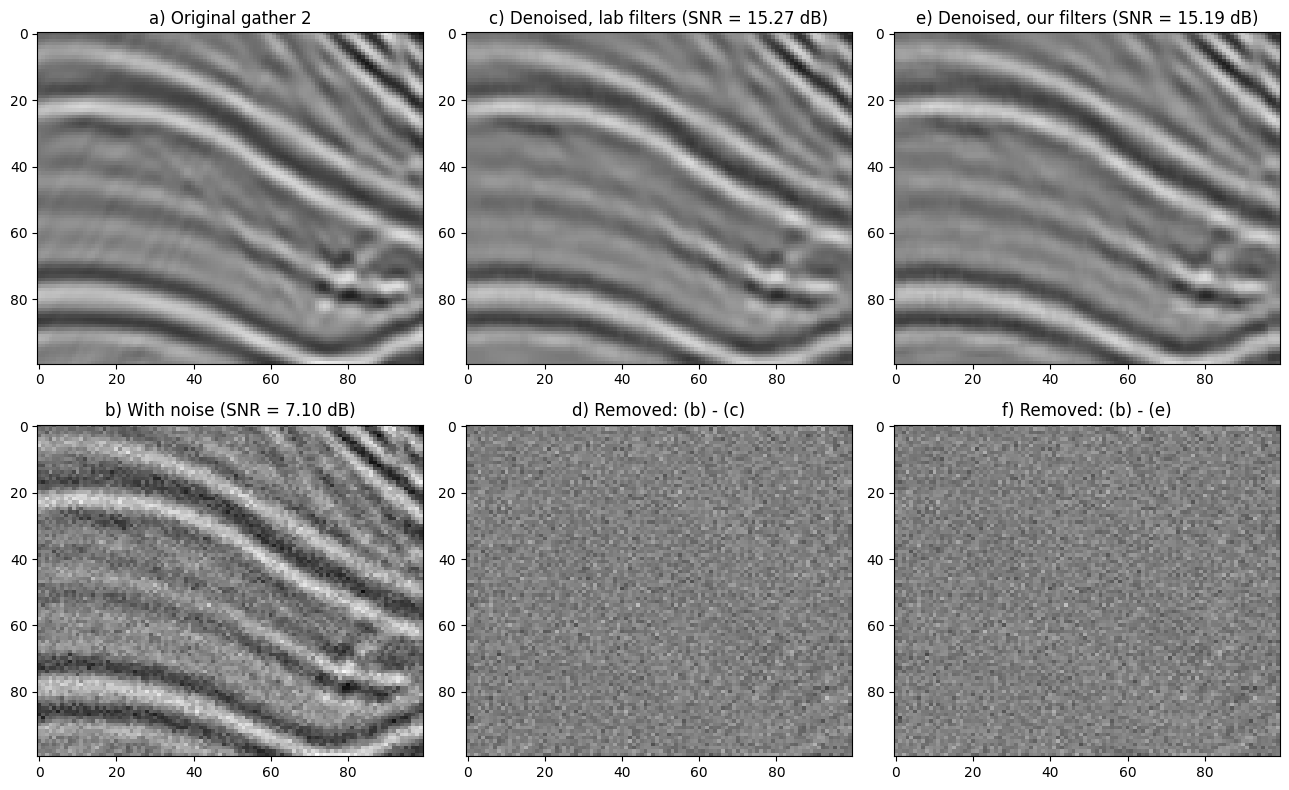

In [6]:
SIGMA = 0.3


def noisy(x, seed, sigma=SIGMA):
    return x + sigma * np.random.default_rng(seed).standard_normal(x.shape)


x_noisy = noisy(x_test, 100)
_, rec_lab = csc_reconstruct(x_noisy, d_lab, lam=0.5)
_, rec_own = csc_reconstruct(x_noisy, d_own, lam=0.5)
print(f"noise seed 100: SNR noisy {snr_db(x_test, x_noisy - x_test):.2f} dB, "
      f"denoised with the lab filters {snr_db(x_test, rec_lab - x_test):.2f} dB, "
      f"with our filters {snr_db(x_test, rec_own - x_test):.2f} dB")

before, after_lab, after_own = [], [], []
for seed in range(100, 105):
    xn = noisy(x_test, seed)
    before.append(snr_db(x_test, xn - x_test))
    after_lab.append(snr_db(x_test, csc_reconstruct(xn, d_lab, lam=0.5)[1] - x_test))
    after_own.append(snr_db(x_test, csc_reconstruct(xn, d_own, lam=0.5)[1] - x_test))
print(f"noise seeds 100-104: noisy {np.mean(before):.2f}, lab filters {np.mean(after_lab):.2f} "
      f"+- {np.std(after_lab):.2f}, our filters {np.mean(after_own):.2f} +- {np.std(after_own):.2f} dB")

panels = [(x_test, "a) Original gather 2"),
          (x_noisy, f"b) With noise (SNR = {snr_db(x_test, x_noisy - x_test):.2f} dB)"),
          (rec_lab, f"c) Denoised, lab filters (SNR = {snr_db(x_test, rec_lab - x_test):.2f} dB)"),
          (x_noisy - rec_lab, "d) Removed: (b) - (c)"),
          (rec_own, f"e) Denoised, our filters (SNR = {snr_db(x_test, rec_own - x_test):.2f} dB)"),
          (x_noisy - rec_own, "f) Removed: (b) - (e)")]
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax, (img, title) in zip(axes.T.ravel(), panels):
    ax.imshow(img, cmap="gray", vmin=-2.5, vmax=2.5, aspect="auto")
    ax.set_title(title)
plt.tight_layout()
plt.show()

The lab reports an SNR of 7.19 dB before and 15.01 dB after denoising. Here the same steps give 7.10 dB before
and 15.27 dB after with the lab's filters, and 15.19 dB with the filters trained above. Over five noise draws
the means are 15.33 and 15.29 dB, with spreads near 0.1 dB. The noise is drawn by NumPy instead of MATLAB's
`randn`, so the numbers cannot match exactly, but the port reproduces the lab within about 0.3 dB. The removed
part (panels d and f) looks like random noise, with no visible trace of the events, so at $\beta=0.5$ the
filters keep the signal and drop most of the noise.

### 3.2 Keeping the spectra Hermitian

The MATLAB code updates the filters and the maps in the Fourier domain and takes the real part of the inverse
FFT at every step, but it keeps working with the complex spectra `d_hat` and `z_hat`. Those spectra are not
exactly Hermitian (the spectrum of a real signal satisfies $\hat{z}(-k)=\overline{\hat{z}(k)}$). In exact
arithmetic the non-Hermitian part would stay zero; in floating point it starts at about $10^{-16}$ and the two
alternating blocks amplify it. The objective is computed from the real $\mathbf{z}$, so the error shows up as a
rise in the objective, and the stopping rule that restores the previous iterate ends training early.
`keep_real=True` recomputes `d_hat` and `z_hat` from the real $\mathbf{d}$ and $\mathbf{z}$ after each update.
This is a projection onto real signals and does not change the problem being solved. The table runs both
variants with six seeds.

seed  keep_real  iterations  objective  SNR (dB)


   0      False          16      575.2     14.92


   0       True          26      569.3     15.19


   1      False          16      578.4     15.03


   1       True          23      573.5     15.02


   2      False          15      571.2     15.04


... (3 outputs left out)

   4      False          15      570.5     15.29


   4       True          26      562.8     15.42


   5      False          15      575.5     15.16


   5       True          23      568.9     15.21


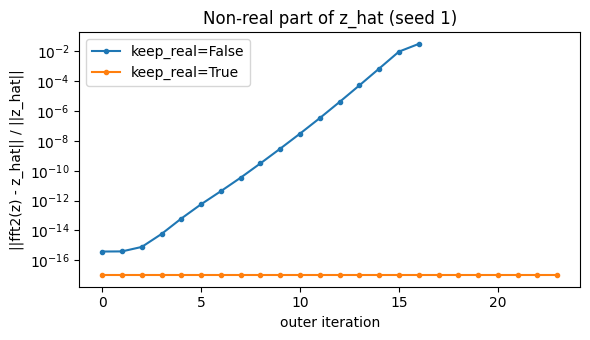

In [7]:
print(f"{'seed':>4}  {'keep_real':>9}  {'iterations':>10}  {'objective':>9}  {'SNR (dB)':>8}")
traces = {}
for seed in range(6):
    for keep_real in (False, True):
        trace = []
        d, _, hist = csc_learn(x_train, (21, 11, 3), rng=np.random.default_rng(seed), keep_real=keep_real,
                               trace=trace)
        snr = snr_db(x_test, csc_reconstruct(x_noisy, d, lam=0.5)[1] - x_test)
        print(f"{seed:>4}  {str(keep_real):>9}  {len(hist) - 1:>10}  {hist[-1]:>9.1f}  {snr:>8.2f}")
        traces[seed, keep_real] = trace

plt.figure(figsize=(6, 3.5))
for keep_real in (False, True):
    plt.semilogy(np.maximum(traces[1, keep_real], 1e-17), "o-", ms=3, label=f"keep_real={keep_real}")
plt.xlabel("outer iteration")
plt.ylabel("||fft2(z) - z_hat|| / ||z_hat||")
plt.title("Non-real part of z_hat (seed 1)")
plt.legend()
plt.tight_layout()
plt.show()

With the MATLAB code as distributed (`keep_real=False`) the non-real part of `z_hat` grows by about one order of
magnitude per outer iteration, from about $10^{-16}$ to $10^{-2}$. Every run then stops after 15 or 16
iterations, when this error starts to raise the objective. With `keep_real=True` the error stays at rounding
level, training runs 23 to 27 iterations until the `tol` test ends it, and the final objective is lower for
every seed (562.8 to 578.9 against 570.5 to 587.9). The SNR after denoising barely changes (15.02 to 15.42 dB
against 14.92 to 15.29 dB, and the old variant is slightly better for two of the six seeds), so the lab's result
does not depend on this detail. The rest of the notebook keeps `keep_real=True`, so that runs with many or large
filters end by convergence and not by a rounding artifact.

## 4. Exercise (a): size and number of filters

Item (a) asks to vary the size and the number of filters in the training phase. Two sweeps start from the lab's
21 x 11 x 3:

- **size**, with $K=3$: 5 x 5, 11 x 5, 11 x 11, 21 x 11, 21 x 21, 31 x 15, 41 x 21 and 61 x 31 samples (rows are
  time, columns are traces);
- **number**, with 21 x 11 filters: $K$ = 1, 2, 3, 6, 12, 24 and 48.

Each configuration is trained with five seeds (training seed $s$ is paired with noise seed $100+s$ on the test
gather, $\sigma=0.3$ as in `denoise.m`), so the spread includes both the random start and the noise. The
denoising phase runs over a grid of $\beta$ values: the table reports the lab's $\beta=0.5$ and the best $\beta$
on the grid, which already looks ahead to item (b). Odd sizes are used because the code builds a support of
$2\lfloor h/2\rfloor+1$ samples, so an even size would silently grow by one.

In [8]:
BETAS = np.array([0.05, 0.1, 0.15, 0.2, 0.3, 0.4, 0.5, 0.75, 1.0, 1.5, 2.0])
SEEDS = range(5)
noisy_test = [noisy(x_test, 100 + s) for s in SEEDS]
SIZES = [(5, 5), (11, 5), (11, 11), (21, 11), (21, 21), (31, 15), (41, 21), (61, 31)]
COUNTS = [1, 2, 3, 6, 12, 24, 48]
size_configs = [(h, w, 3) for h, w in SIZES]
count_configs = [(21, 11, K) for K in COUNTS]


def run_config(kernel_size):
    '''Train with seeds 0-4; denoise the test gather (noise seed 100 + s) over the beta grid.'''
    res = {"obj": [], "its": [], "time": [], "snr": [], "filters": []}
    for s in SEEDS:
        t0 = time.time()
        d, _, hist = csc_learn(x_train, kernel_size, rng=np.random.default_rng(s))
        res["time"].append(time.time() - t0)
        res["obj"].append(hist[-1])
        res["its"].append(len(hist) - 1)
        res["snr"].append([snr_db(x_test, csc_reconstruct(noisy_test[s], d, lam=beta)[1] - x_test)
                           for beta in BETAS])
        res["filters"].append(d)
    for key in ("obj", "its", "time", "snr"):
        res[key] = np.array(res[key])
    return res


i05 = int(np.where(BETAS == 0.5)[0][0])
print(f"{'filters':>12}  {'objective':>9}  {'iters':>5}  {'time':>6}  {'SNR at beta=0.5':>15}  "
      f"{'best beta':>9}  {'SNR at best beta':>16}")
sweep = {}
for ks in size_configs + [c for c in count_configs if c not in size_configs]:
    res = sweep[ks] = run_config(ks)
    mean = res["snr"].mean(axis=0)
    ib = int(np.argmax(mean))
    print(f"{'%d x %d x %d' % ks:>12}  {res['obj'].mean():>9.0f}  {res['its'].mean():>5.1f}  "
          f"{res['time'].mean():>5.1f}s  {mean[i05]:>9.2f} +- {res['snr'][:, i05].std():.2f}  "
          f"{BETAS[ib]:>9}  {mean[ib]:>10.2f} +- {res['snr'][:, ib].std():.2f}")

     filters  objective  iters    time  SNR at beta=0.5  best beta  SNR at best beta


   5 x 5 x 3        868   15.4    0.5s      12.70 +- 0.17        0.3       13.20 +- 0.33


  11 x 5 x 3        726   20.6    0.7s      14.23 +- 0.06        0.4       14.45 +- 0.13


 11 x 11 x 3        622   21.2    0.7s      15.24 +- 0.18        0.3       15.78 +- 0.20


 21 x 11 x 3        570   25.4    0.9s      15.20 +- 0.24        0.3       16.03 +- 0.27


 21 x 21 x 3        507   46.0    1.7s      15.10 +- 0.15        0.2       16.35 +- 0.30


... (5 outputs left out)

 21 x 11 x 6        517   31.2    1.6s      15.84 +- 0.23        0.3       16.14 +- 0.30


21 x 11 x 12        475   51.8    4.4s      16.02 +- 0.12        0.5       16.02 +- 0.12


21 x 11 x 24        445   56.0    9.2s      16.08 +- 0.12        0.5       16.08 +- 0.12


21 x 11 x 48        427   64.0   21.5s      15.87 +- 0.12        0.5       15.87 +- 0.12


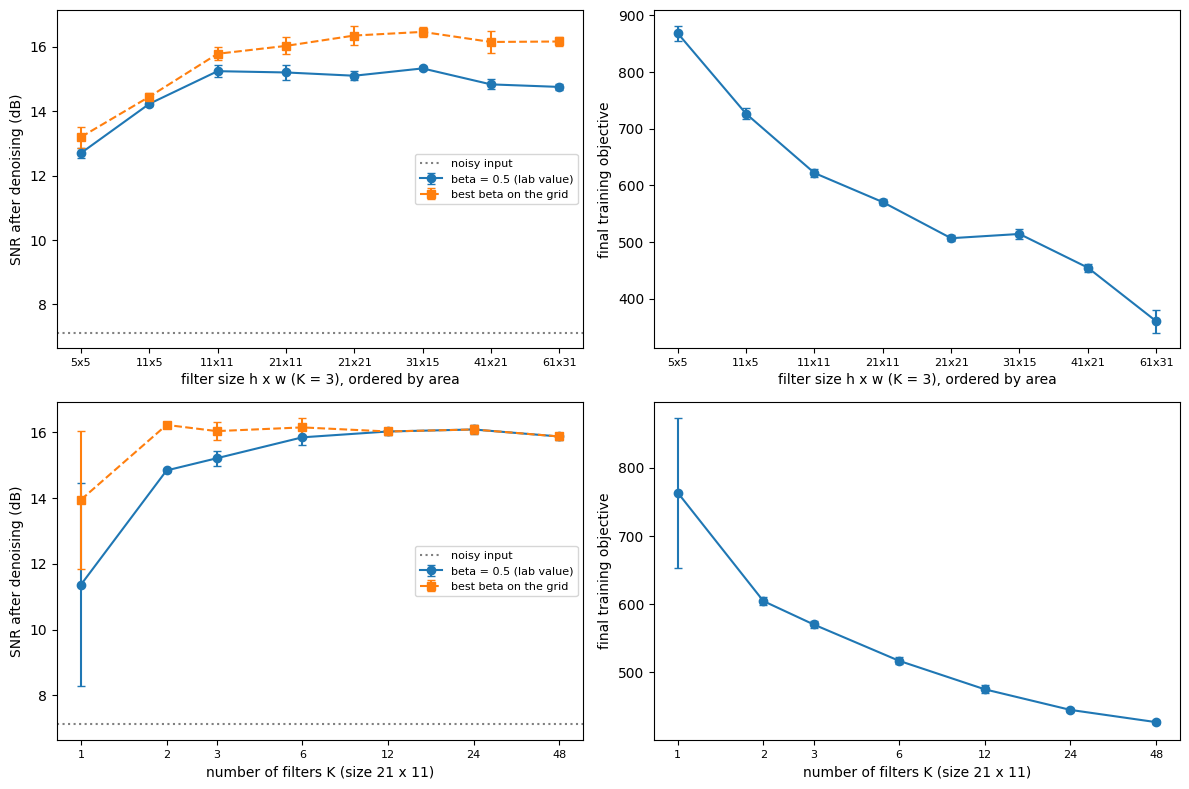

In [9]:
def summary(configs):
    snr05 = np.array([sweep[c]["snr"][:, i05] for c in configs])
    best = np.array([sweep[c]["snr"][:, int(np.argmax(sweep[c]["snr"].mean(axis=0)))] for c in configs])
    obj = np.array([sweep[c]["obj"] for c in configs])
    return snr05, best, obj


fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for row, (configs, xs, labels, xlabel) in enumerate([
        (size_configs, list(range(len(size_configs))), ["%dx%d" % (h, w) for h, w, _ in size_configs],
         "filter size h x w (K = 3), ordered by area"),
        (count_configs, COUNTS, [str(K) for K in COUNTS], "number of filters K (size 21 x 11)")]):
    snr05, best, obj = summary(configs)
    ax = axes[row, 0]
    ax.errorbar(xs, snr05.mean(axis=1), snr05.std(axis=1), fmt="o-", capsize=3, label="beta = 0.5 (lab value)")
    ax.errorbar(xs, best.mean(axis=1), best.std(axis=1), fmt="s--", capsize=3, label="best beta on the grid")
    ax.axhline(np.mean([snr_db(x_test, xn - x_test) for xn in noisy_test]), color="gray", ls=":",
               label="noisy input")
    ax.set_ylabel("SNR after denoising (dB)")
    ax.legend(fontsize=8)
    ax = axes[row, 1]
    ax.errorbar(xs, obj.mean(axis=1), obj.std(axis=1), fmt="o-", capsize=3)
    ax.set_ylabel("final training objective")
    for ax in axes[row]:
        if row == 1:
            ax.set_xscale("log")
        ax.set_xticks(xs)
        ax.set_xticklabels(labels, fontsize=8)
        ax.minorticks_off()
        ax.set_xlabel(xlabel)
plt.tight_layout()
plt.show()

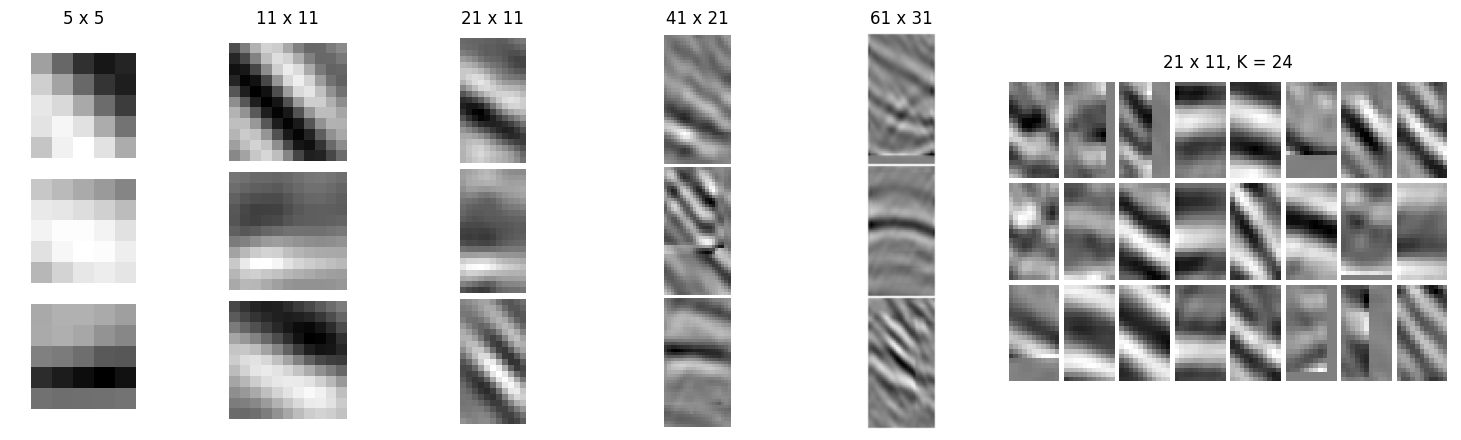

In [10]:
fig, axes = plt.subplots(1, 6, figsize=(15, 4.5), gridspec_kw={"width_ratios": [1, 1, 1, 1, 1, 2.2]})
for ax, ks in zip(axes, [(5, 5, 3), (11, 11, 3), (21, 11, 3), (41, 21, 3), (61, 31, 3)]):
    show_mosaic(ax, sweep[ks]["filters"][0], "%d x %d" % ks[:2], ncols=1)
show_mosaic(axes[5], sweep[(21, 11, 24)]["filters"][0], "21 x 11, K = 24", ncols=8)
plt.tight_layout()
plt.show()

**Filter size.** The training objective falls steadily as the filters grow, from 868 for 5 x 5 to 360 for 61 x
31, because larger filters can fit more of the gather. Denoising does not follow it. At the lab's $\beta=0.5$
the SNR rises from 12.70 dB (5 x 5) to 15.24 dB (11 x 11), stays between 15.1 and 15.3 dB up to 31 x 15, and
falls to about 14.8 dB for 41 x 21 and 61 x 31. With $\beta$ tuned, the best result is 16.46 dB for 31 x 15, and
the largest filters reach 16.15 to 16.17 dB.

The galleries explain both ends. The dominant period of the events is about 14 samples (the spectrum of the
gather in Section 6 peaks near 0.07 cycles per sample), so a 5 x 5 filter cannot hold one wavelength and turns
into ramps and edges. Even 11 x 5 is short. This is the rule given in the chapter: a filter should be longer
than one wavelength. At the other end, the 41 x 21 and 61 x 31 filters are no longer single wavelets but whole
pieces of the training gather, with several events, crossings and sharp cuts. The low objective then comes from
memorizing gather 1. Gather 2 matches these patterns less well, so a strong l1 penalty removes its events
sooner: the best $\beta$ moves down to 0.2 and the SNR at $\beta=0.5$ drops. Larger filters also cost more: the
61 x 31 runs need 58 outer iterations on average against 25 for 21 x 11. Filters of 11 x 11 to 31 x 15 work best
here; the lab's 21 x 11 is a sensible choice inside that range.

**Number of filters.** One filter is not enough. With $K=1$ the SNR at $\beta=0.5$ is 11.36 dB with a spread of
3.09 dB: two of the five seeds stop after 10 iterations with an objective near 895 (against 650 to 710 for the
other seeds), a poor local minimum of the bi-convex problem, and one of them reaches only 5.7 dB. Two filters
already give 16.22 dB at the best $\beta$. Beyond that the best SNR stays between 15.87 and 16.22 dB: 3 filters
give 16.03, 6 give 16.14, 12 give 16.02, 24 give 16.08 and 48 give 15.87 dB. What more filters change is the
best $\beta$, which moves from 0.2 to 0.3 up to 0.5, and the SNR at the lab's $\beta=0.5$, which rises from
15.20 dB ($K=3$) to 16.08 dB ($K=24$). With many filters, events of any dip and curvature have a matching atom,
so a stronger l1 penalty can be used without losing signal. The cost grows quickly (21 s per training run for
$K=48$ against 0.9 s for $K=3$), and $K=48$ is already slightly worse. The $K=24$ gallery shows why: most
filters are wavelets at different dips, but several are near copies of each other and a few contain a sharp cut,
pieces of the training gather with no general meaning.

In short, filter size matters more than filter count: the filters must be longer than a wavelength but not so
large that they copy the training gather, and a handful of filters covering the main dips is enough.

## 5. Exercise (b): the l1 coefficient in the denoising phase

Item (b) asks to vary $\beta$, the coefficient of the l1 norm, in the denoising phase. The curves below reuse
the sweep of Section 4, so each point is a mean over five trained filter sets and noise draws.

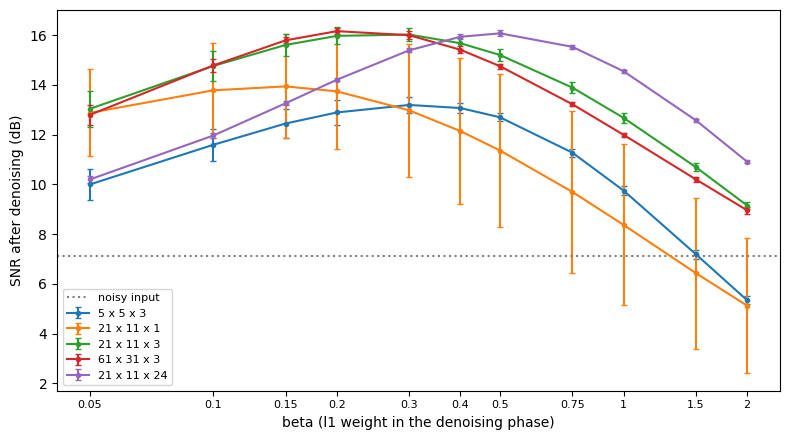

In [11]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for ks in [(5, 5, 3), (21, 11, 1), (21, 11, 3), (61, 31, 3), (21, 11, 24)]:
    snr = sweep[ks]["snr"]
    ax.errorbar(BETAS, snr.mean(axis=0), snr.std(axis=0), fmt="o-", ms=3, capsize=2, label="%d x %d x %d" % ks)
ax.axhline(np.mean([snr_db(x_test, xn - x_test) for xn in noisy_test]), color="gray", ls=":", label="noisy input")
ax.set_xscale("log")
ax.set_xticks(BETAS)
ax.set_xticklabels([f"{beta:g}" for beta in BETAS], fontsize=8)
ax.minorticks_off()
ax.set_xlabel("beta (l1 weight in the denoising phase)")
ax.set_ylabel("SNR after denoising (dB)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

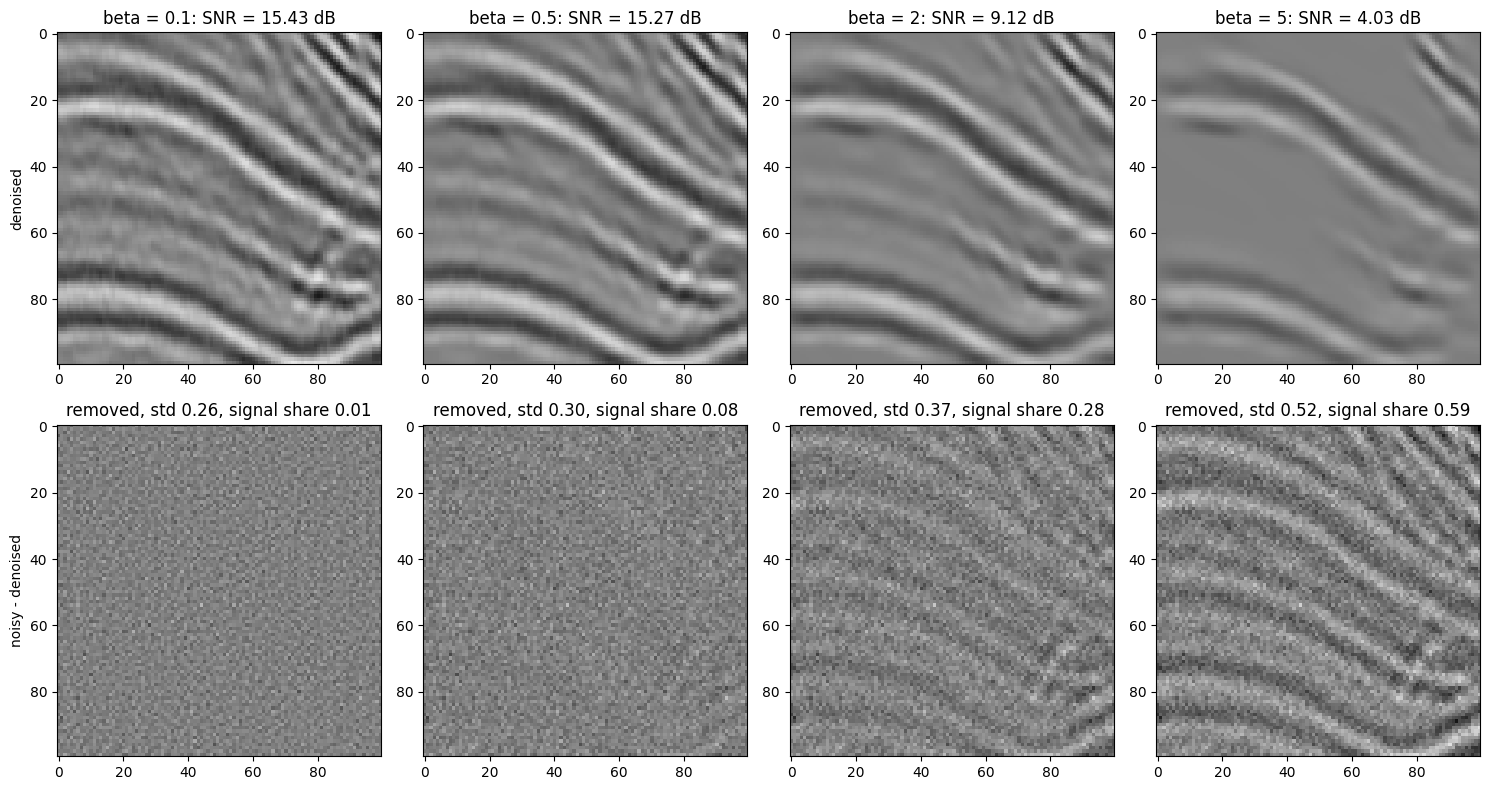

In [12]:
show_betas = [0.1, 0.5, 2.0, 5.0]
fig, axes = plt.subplots(2, 4, figsize=(15, 8))
for j, beta in enumerate(show_betas):
    _, rec = csc_reconstruct(x_noisy, d_lab, lam=beta)
    axes[0, j].imshow(rec, cmap="gray", vmin=-2.5, vmax=2.5, aspect="auto")
    axes[0, j].set_title(f"beta = {beta:g}: SNR = {snr_db(x_test, rec - x_test):.2f} dB")
    removed = x_noisy - rec
    leak = np.sum(removed * x_test) / np.sum(x_test ** 2)
    axes[1, j].imshow(removed, cmap="gray", vmin=-2.5, vmax=2.5, aspect="auto")
    axes[1, j].set_title(f"removed, std {removed.std():.2f}, signal share {leak:.2f}")
axes[0, 0].set_ylabel("denoised")
axes[1, 0].set_ylabel("noisy - denoised")
plt.tight_layout()
plt.show()

Every curve has the same shape. A small $\beta$ leaves noise in the output, because the coefficient maps are
allowed to grow wherever the noise happens to correlate with a filter. A large $\beta$ shrinks the coefficients
so much that weak events disappear too. The best $\beta$ lies between these two failures: 0.2 to 0.3 for $K=3$,
0.15 for $K=1$, and 0.5 for $K=24$. The $K=24$ curve sits lower for small $\beta$ (more filters fit noise more
easily) and higher for large $\beta$ (more filters keep the signal with fewer coefficients).

The images use the lab's filters on one noise draw, in the same way as Fig. 15.7 of the book. At $\beta=0.1$ the
output is still grainy: the removed part has a standard deviation of 0.26, below the true $\sigma=0.3$, and
almost none of the signal (its projection on the clean gather is 0.01 of the signal). At $\beta=0.5$ the removed
part has the noise level, 0.30, and only 8% of the signal leaks into it. At $\beta=2$ and $\beta=5$ the events
show clearly in the removed part (28% and 59% of the signal), the weak events vanish from the output, and the
SNR falls to 9.12 and 4.03 dB. This is the trade-off described in the chapter: a larger $\beta$ removes more
noise but also removes signal.

sigma = 0.15: noisy 13.14 dB, best beta 0.1 (20.34 dB), beta = 0.5 gives 16.34 dB


sigma = 0.3: noisy 7.12 dB, best beta 0.2 (16.43 dB), beta = 0.5 gives 15.33 dB


sigma = 0.6: noisy 1.10 dB, best beta 0.5 (12.32 dB), beta = 0.5 gives 12.32 dB


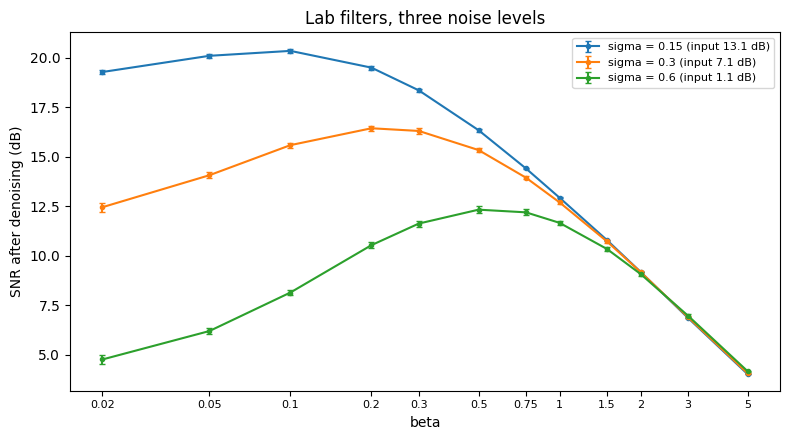

In [13]:
wide = np.array([0.02, 0.05, 0.1, 0.2, 0.3, 0.5, 0.75, 1.0, 1.5, 2.0, 3.0, 5.0])
fig, ax = plt.subplots(figsize=(8, 4.5))
for sigma in (0.15, 0.3, 0.6):
    noisy_s = [noisy(x_test, 100 + s, sigma) for s in SEEDS]
    snr = np.array([[snr_db(x_test, csc_reconstruct(xn, d_lab, lam=beta)[1] - x_test) for beta in wide]
                    for xn in noisy_s])
    ib = int(np.argmax(snr.mean(axis=0)))
    snr_in = np.mean([snr_db(x_test, xn - x_test) for xn in noisy_s])
    print(f"sigma = {sigma}: noisy {snr_in:.2f} dB, best beta {wide[ib]:g} ({snr.mean(axis=0)[ib]:.2f} dB), "
          f"beta = 0.5 gives {snr.mean(axis=0)[list(wide).index(0.5)]:.2f} dB")
    ax.errorbar(wide, snr.mean(axis=0), snr.std(axis=0), fmt="o-", ms=3, capsize=2,
                label=f"sigma = {sigma} (input {snr_in:.1f} dB)")
ax.set_xscale("log")
ax.set_xticks(wide)
ax.set_xticklabels([f"{beta:g}" for beta in wide], fontsize=8)
ax.minorticks_off()
ax.set_xlabel("beta")
ax.set_ylabel("SNR after denoising (dB)")
ax.set_title("Lab filters, three noise levels")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [14]:
size_x_lab = (x_test.shape[0] + 20, x_test.shape[1] + 10)
dhat_lab = psf2otf(d_lab, size_x_lab)
print(f"{'beta':>5}  {'iters':>5}  {'objective':>9}  {'SNR (dB)':>8}    {'iters':>5}  {'objective':>9}  {'SNR (dB)':>8}")
print(f"{'':>5}  {'max_it = 80, tol = 1e-3':^26}    {'max_it = 2000, tol = 1e-6':^26}")
for beta in (0.1, 0.3, 0.5, 1.0, 2.0):
    line = f"{beta:>5}"
    for max_it, tol in ((80, 1e-3), (2000, 1e-6)):
        z, rec, it = csc_reconstruct(x_noisy, d_lab, lam=beta, max_it=max_it, tol=tol, return_info=True)
        obj = csc_objective(z[..., None], dhat_lab, x_noisy[..., None], 1.0, beta, (10, 5))
        line += f"  {it:>5}  {obj:>9.1f}  {snr_db(x_test, rec - x_test):>8.2f}  "
    print(line)

 beta  iters  objective  SNR (dB)    iters  objective  SNR (dB)
        max_it = 80, tol = 1e-3      max_it = 2000, tol = 1e-6 


  0.1     80      448.9     15.43     2000      442.6     15.28  


  0.3     80      611.6     16.22     2000      605.0     15.96  


  0.5     80      742.2     15.27     2000      732.9     15.11  


  1.0     80     1018.3     12.64     2000     1003.6     12.65  


  2.0     80     1453.4      9.12     2000     1432.5      9.21  


The best $\beta$ grows with the noise: 0.1 for $\sigma=0.15$, 0.2 for $\sigma=0.3$ and 0.5 for $\sigma=0.6$.
This is what the l1 term should do. The soft threshold has to sit above the noise in the coefficients, so it
scales with the noise standard deviation, as in classic wavelet thresholding. The lab's $\beta=0.5$ is the best
choice only for the strongest noise; for the lab's own $\sigma=0.3$ it gives 15.33 dB against 16.43 dB at
$\beta=0.2$, and for $\sigma=0.15$ it loses 4 dB. For large $\beta$ the three curves meet, because the error is
then the lost signal, which does not depend on the noise. In practice $\beta$ should be set from an estimate of
the noise level, not left at a fixed value.

The last table checks how far 80 ADMM iterations are from the minimizer. None of the runs meets `tol = 1e-3`
before `max_it = 80`. Running 2000 iterations lowers the objective by 1% to 2% and changes the SNR by 0.26 dB or
less: it drops slightly for $\beta \le 0.5$ and rises slightly for $\beta \ge 1$. So the early stop acts as a
small extra smoothing, but the ranking of the $\beta$ values, with the best near 0.3, is the same in both
columns.

## 6. Exercise (c): CSC filters and the first layer of a CNN

To compare like with like, a small CNN denoiser is trained on the same gather 1 with a first layer of 24 filters
of 21 x 11 samples, the same shape as the CSC run with $K=24$. The network is Conv(1 to 24, 21 x 11), ReLU,
Conv(24 to 24, 3 x 3), ReLU, Conv(24 to 1, 3 x 3). Training takes random 64 x 64 crops of gather 1 with random
left-right flips, adds fresh noise with $\sigma=0.3$ at each step, and minimizes the mean squared error to the
clean crop with Adam (learning rate $10^{-3}$, 3000 steps of 16 crops). Unlike CSC, this training is supervised:
it needs the clean gather and the noise model. The test uses the same noisy versions of gather 2 as Section 4.

In [15]:
torch.manual_seed(0)
K_CNN = 24
cnn = nn.Sequential(nn.Conv2d(1, K_CNN, (21, 11), padding="same"), nn.ReLU(),
                    nn.Conv2d(K_CNN, K_CNN, 3, padding="same"), nn.ReLU(),
                    nn.Conv2d(K_CNN, 1, 3, padding="same"))
X1 = torch.tensor(x_train, dtype=torch.float32)
opt = torch.optim.Adam(cnn.parameters(), 1e-3)
g = torch.Generator().manual_seed(0)
t0 = time.time()
for step in range(3000):
    i, j = torch.randint(0, 37, (16,), generator=g), torch.randint(0, 37, (16,), generator=g)
    batch = torch.stack([X1[a:a + 64, c:c + 64] for a, c in zip(i, j)])[:, None]
    flip = torch.rand(16, generator=g) < 0.5
    batch[flip] = batch[flip].flip(-1)
    noisy_batch = batch + SIGMA * torch.randn(batch.shape, generator=g)
    loss = ((cnn(noisy_batch) - batch) ** 2).mean()
    opt.zero_grad()
    loss.backward()
    opt.step()
print(f"CNN trained for 3000 steps in {time.time() - t0:.0f} s, last batch MSE {loss.item():.4f}")

with torch.no_grad():
    cnn_out = [cnn(torch.tensor(xn, dtype=torch.float32)[None, None])[0, 0].numpy() for xn in noisy_test]
snr_cnn = [snr_db(x_test, out - x_test) for out in cnn_out]
csc24 = sweep[(21, 11, 24)]["snr"]
ib24 = int(np.argmax(csc24.mean(axis=0)))
print(f"test gather 2, noise seeds 100-104: CNN {np.mean(snr_cnn):.2f} +- {np.std(snr_cnn):.2f} dB, "
      f"CSC 21 x 11 x 24 at beta = {BETAS[ib24]:g}: {csc24[:, ib24].mean():.2f} +- {csc24[:, ib24].std():.2f} dB")

CNN trained for 3000 steps in 116 s, last batch MSE 0.0070
test gather 2, noise seeds 100-104: CNN 17.31 +- 0.16 dB, CSC 21 x 11 x 24 at beta = 0.5: 16.08 +- 0.12 dB


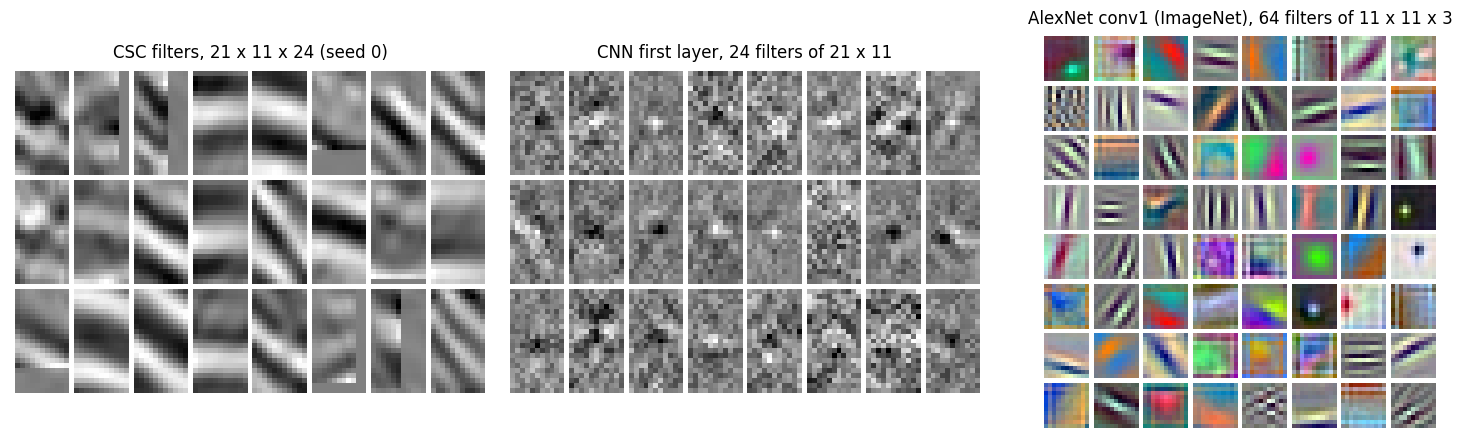

In [16]:
d_csc = sweep[(21, 11, 24)]["filters"][0]
w1 = np.moveaxis(cnn[0].weight.detach().numpy()[:, 0], 0, 2)  # (21, 11, 24)

try:
    import torchvision
    alex = torchvision.models.alexnet(weights="IMAGENET1K_V1").features[0].weight.detach().numpy()
except Exception as err:  # no torchvision or no network: skip the ImageNet panel
    alex = None
    print("AlexNet weights not available:", err)

fig, axes = plt.subplots(1, 3 if alex is not None else 2, figsize=(15, 4.5))
show_mosaic(axes[0], d_csc, "CSC filters, 21 x 11 x 24 (seed 0)", ncols=8)
show_mosaic(axes[1], w1, "CNN first layer, 24 filters of 21 x 11", ncols=8)
if alex is not None:
    tiles = np.ones((8 * 12 + 1, 8 * 12 + 1, 3))
    for k in range(64):
        f = np.transpose(alex[k], (1, 2, 0))
        f = (f - f.min()) / (f.max() - f.min())
        i, j = divmod(k, 8)
        tiles[1 + 12 * i:12 + 12 * i, 1 + 12 * j:12 + 12 * j] = f
    axes[2].imshow(tiles)
    axes[2].set_title("AlexNet conv1 (ImageNet), 64 filters of 11 x 11 x 3")
    axes[2].axis("off")
plt.tight_layout()
plt.show()

mean best normalized cross-correlation with the CSC filters (seed 0):
  CNN first layer        0.40
  CSC, training seed 1   0.87
  random filters         0.18


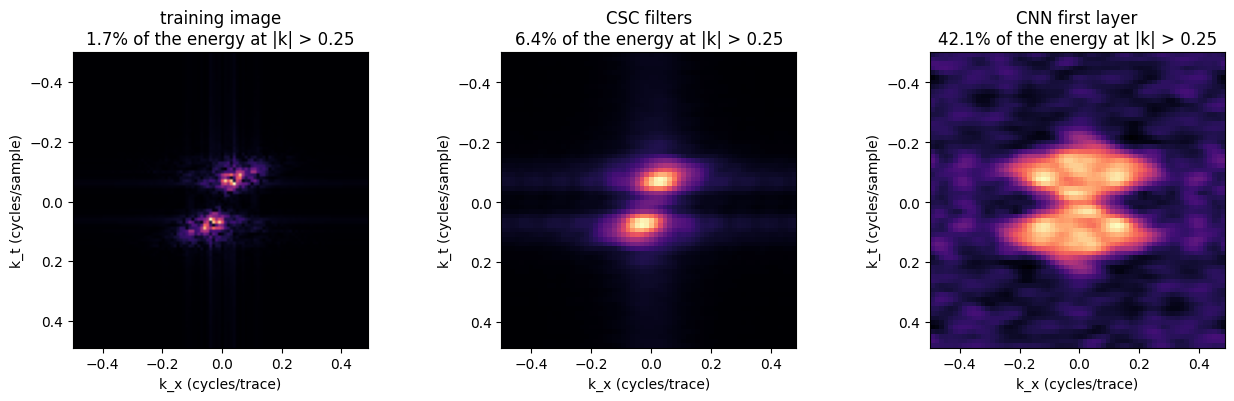

In [17]:
def ncc(a, c):
    '''Largest normalized cross-correlation over all shifts, sign ignored.'''
    return np.abs(correlate2d(a, c, mode="full")).max() / np.linalg.norm(a) / np.linalg.norm(c)


def best_match(F, G):
    return np.array([max(ncc(F[:, :, i], G[:, :, j]) for j in range(G.shape[2])) for i in range(F.shape[2])])


d_csc_b = sweep[(21, 11, 24)]["filters"][1]  # same configuration, training seed 1
rand = np.random.default_rng(0).standard_normal((21, 11, 24))
print("mean best normalized cross-correlation with the CSC filters (seed 0):")
for name, F in [("CNN first layer", w1), ("CSC, training seed 1", d_csc_b), ("random filters", rand)]:
    print(f"  {name:<22} {best_match(F, d_csc).mean():.2f}")


def amplitude_spectrum(F, n=64):
    return np.fft.fftshift(np.mean([np.abs(np.fft.fft2(F[:, :, k], (n, n))) for k in range(F.shape[2])], axis=0))


f64 = np.fft.fftshift(np.fft.fftfreq(64))
f100 = np.fft.fftshift(np.fft.fftfreq(100))
spectra = [("training image", np.fft.fftshift(np.abs(np.fft.fft2(x_train))), f100),
           ("CSC filters", amplitude_spectrum(d_csc), f64),
           ("CNN first layer", amplitude_spectrum(w1), f64)]
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (name, S, f) in zip(axes, spectra):
    KY, KX = np.meshgrid(f, f, indexing="ij")
    high = (S[np.hypot(KY, KX) > 0.25] ** 2).sum() / (S ** 2).sum()
    ax.imshow(S, cmap="magma", extent=[f[0], f[-1], f[-1], f[0]])
    ax.set_title(f"{name}\n{high:.1%} of the energy at |k| > 0.25")
    ax.set_xlabel("k_x (cycles/trace)")
    ax.set_ylabel("k_t (cycles/sample)")
plt.tight_layout()
plt.show()

The CNN denoises better than CSC on these test images, 17.31 dB against 16.08 dB for CSC with 24 filters at its
best $\beta$. The comparison is not neutral, though: the CNN was trained with clean targets and with the exact
noise model of the test, while CSC never saw clean data or noise, only one high-SNR gather.

**Similarities.** Both are banks of small filters slid over the whole gather, so both use shared weights and
treat every position the same way (translation invariance). Both are learned from the same gather 1, have the
same size here, and act as the first stage that turns the gather into $K$ feature maps. The mean spectrum of the
CNN filters, like the CSC one, peaks at the temporal frequencies of the events, although it is much broader. The
CNN filters are closer to the CSC filters than random filters are (mean best normalized cross-correlation 0.40
against 0.18).

**Differences.** The match is still weak: two CSC runs with different seeds agree at 0.87, so the CNN learned a
different bank. The CSC filters are smooth wavelets that look like the events, and only 6.4% of their spectral
energy lies above 0.25 cycles per sample, close to the 1.7% of the gather. The CNN filters are a small central
spot inside a noisy surround, with 42.1% of their energy at high wavenumbers. The reason is the role of each
bank. In CSC the filters are *synthesis* atoms: the output is $\sum_k \mathbf{d}_k*\mathbf{z}_k$, so a filter
must look like the signal, and each one is held to its support and to unit norm. In the CNN they are *analysis*
filters: the output of layer 1 is $\mathrm{ReLU}(\mathbf{W}*\mathbf{x}+\mathbf{b})$, which later layers combine,
and the loss only asks for a good final output. Weights far from the center have little effect on that loss, and
no norm constraint or sparsity penalty pulls them to zero, so they stay noisy. Other differences are the
training signal (unsupervised reconstruction with sparsity against a supervised denoising loss) and how the
features are computed (an iterative optimization for every new gather against one forward pass).

The ImageNet filters of AlexNet's first layer, the textbook picture of first-layer CNN filters, are oriented
edges, gratings and color blobs. With a large and varied training set, first-layer CNN filters become localized,
oriented and band-pass, which is also what sparse coding learns from natural images (Olshausen and Field, 1996).
Here the CSC filters show that structure and the small CNN, trained on one gather, only partly does.

In [18]:
d24, beta = d_csc, BETAS[ib24]
xn = noisy_test[0]
dhat = psf2otf(d24, size_x)
L = np.max(np.sum(np.abs(dhat) ** 2, axis=2))  # Lipschitz constant of the data-term gradient
xp = np.pad(xn, [(10, 10), (5, 5)])
mask = np.pad(np.ones_like(xn), [(10, 10), (5, 5)])


def D(z):
    return ifft2_real(np.sum(dhat * fft2(z), axis=2))


def Dt(v):
    return ifft2_real(np.conj(dhat) * fft2(v)[..., None])


z = np.zeros(size_x + (24,))
print(f"ISTA with the 21 x 11 x 24 CSC filters, beta = {beta:g}, noise seed 100")
print(f"{'iterations':>10}  {'SNR (dB)':>8}  {'SNR, best scale':>15}  {'nonzero z':>9}")
for t in range(1, 1001):
    z = soft(z + Dt(mask * (xp - D(z))) / L, beta / L)
    if t in (1, 2, 5, 10, 30, 100, 300, 1000):
        rec = crop(D(z), (10, 5))
        a = np.sum(rec * x_test) / np.sum(rec ** 2)
        print(f"{t:>10}  {snr_db(x_test, rec - x_test):>8.2f}  {snr_db(x_test, a * rec - x_test):>15.2f}  "
              f"{np.mean(z != 0):>9.1%}")

with torch.no_grad():
    act = torch.relu(cnn[0](torch.tensor(xn, dtype=torch.float32)[None, None])).numpy()
print(f"CNN first layer after ReLU on the same input: {np.mean(act > 0):.1%} of the activations are nonzero")

ISTA with the 21 x 11 x 24 CSC filters, beta = 0.5, noise seed 100
iterations  SNR (dB)  SNR, best scale  nonzero z
         1      5.90             7.79      77.9%
         2      8.22             9.50      74.6%
         5     11.14            12.26      62.0%
        10     12.99            14.15      49.5%
        30     14.90            15.99      30.6%


       100     15.86            16.69      15.6%


       300     16.21            16.79       7.7%


      1000     16.25            16.63       3.4%
CNN first layer after ReLU on the same input: 52.7% of the activations are nonzero


The link between the two methods is explicit for ISTA, the simplest solver of the same sparse coding problem
(Papyan et al., 2017, cited at the start of Chapter 15). One ISTA step from $\mathbf{z}=0$ gives
$\mathbf{z}_k=\mathrm{soft}(\mathbf{d}_k\star\mathbf{x}/L,\ \beta/L)$, where $\star$ is correlation. This is a
convolutional layer whose weights are the dictionary filters, with a bias of $-\beta/L$ and a two-sided ReLU as
the activation. A CNN layer is therefore one step of a sparse pursuit.

The table shows how far one step is from the solution. After one iteration the SNR is 5.90 dB (7.79 dB with the
best scaling), not better than the noisy input; it takes about 30 iterations to reach 14.90 dB and 300 to reach
16.21 dB. Meanwhile the fraction of nonzero coefficients falls from 77.9% to 3.4%, while the CNN's first layer
leaves 52.7% of its activations nonzero. A CNN makes up for its single step by learning its filters, biases and
deeper layers end to end for the task, which is the idea behind learned ISTA (Gregor and LeCun, 2010). CSC
instead spends many iterations on every new gather, but needs neither clean targets nor a noise model to learn
its filters.

## Discussion

The NumPy port reproduces the lab: with the lab's settings, the denoised gather 2 reaches 15.2 to 15.3 dB from
7.1 dB, against 15.01 dB reported in the lab, with either the lab's filters or new ones. One numerical detail of
the original code, the loss of Hermitian symmetry in the Fourier-domain updates, was found and corrected; it
ends training early but has little effect on denoising.

(a) Filter size matters more than filter count. Filters shorter than one wavelength (5 x 5) cannot describe an
event and lose about 3 dB. Very large filters (41 x 21 and above) reach the lowest training objective by copying
pieces of the training gather and generalize slightly worse. Between 11 x 11 and 31 x 15 the results are close,
with the best at 31 x 15. One filter is unreliable, since its training often stops in a poor local minimum, but
from two filters on the best SNR stays near 16 dB; more filters mainly allow a larger $\beta$ and cost more
time.

(b) $\beta$ trades noise left in the output against signal removed with the noise. The SNR peaks at an
intermediate $\beta$, and the best value scales with the noise level (0.1, 0.2 and 0.5 for $\sigma$ = 0.15, 0.3
and 0.6). The lab's $\beta=0.5$ is about 1 dB below the best for its own noise level.

(c) CSC filters and first-layer CNN filters are both shared, translation-invariant banks of small filters
learned from data, and they meet formally: one ISTA step of sparse coding is a convolutional layer with a
thresholding activation. They differ in role and in training. CSC filters are synthesis atoms constrained to
unit norm and learned without labels, so they look like the seismic events. CNN filters are analysis filters
trained for a supervised loss, and here they are broadband and noisy. The CNN denoises about 1.2 dB better, but
only because it was given clean data and the exact noise model, which field data does not provide.

The results come from one training gather and one test gather, with synthetic Gaussian noise added after the
contrast normalization, so the numbers describe this setting and not field noise, which is often coherent.

**References**

- Gregor, K., and LeCun, Y. (2010), Learning fast approximations of sparse coding, *ICML*.
- Heide, F., Heidrich, W., and Wetzstein, G. (2015), Fast and flexible convolutional sparse coding, *CVPR*.
- Olshausen, B. A., and Field, D. J. (1996), Emergence of simple-cell receptive field properties by learning a
  sparse code for natural images, *Nature*, 381, 607-609.
- Papyan, V., Romano, Y., and Elad, M. (2017), Convolutional neural networks analyzed via convolutional sparse
  coding, *Journal of Machine Learning Research*, 18, 1-52.
- Schuster, G. (2024), *Machine Learning Methods in Geoscience*, SEG, Chapter 15.